In [5]:
import lancedb
import polars as pl
from scipy.spatial import distance
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt
import numpy as np
import random

In [2]:
uri = "../../data/pokemon_db"
db = lancedb.connect(uri)

db.list_tables()

ListTablesResponse(context=None, tables=['pokemon'], page_token=None)

In [3]:
table = db.open_table("pokemon")
df = table.search().to_polars()

df

dex_num,name,page_title,image_path,text,image_vector,text_vector
str,str,str,str,str,"array[f32, 1024]","array[f32, 1024]"
"""0001""","""Bulbasaur""","""Bulbasaur (Pokémon)""","""data/pokemon_data/images/0001_…","""Bulbasaur is a small, quadrupe…","[0.009552, 0.042646, … 0.012425]","[0.488401, 2.604806, … -0.158971]"
"""0002""","""Ivysaur""","""Ivysaur (Pokémon)""","""data/pokemon_data/images/0002_…","""Ivysaur is a quadrupedal amphi…","[0.009569, 0.043917, … 0.023321]","[3.156766, 2.03966, … 2.216954]"
"""0003""","""Venusaur""","""Venusaur (Pokémon)""","""data/pokemon_data/images/0003_…","""Venusaur is a squat, quadruped…","[0.019082, 0.030828, … 0.004789]","[3.346082, 3.002894, … -1.35448]"
"""0004""","""Charmander""","""Charmander (Pokémon)""","""data/pokemon_data/images/0004_…","""Charmander is a bipedal, repti…","[0.007554, 0.030683, … 0.00532]","[-2.461749, 2.43778, … 0.304722]"
"""0005""","""Charmeleon""","""Charmeleon (Pokémon)""","""data/pokemon_data/images/0005_…","""Charmeleon is a bipedal, repti…","[0.022615, 0.02371, … 0.013143]","[0.909607, 4.071574, … -0.847041]"
…,…,…,…,…,…,…
"""1020""","""Gouging Fire""","""Gouging Fire (Pokémon)""","""data/pokemon_data/images/1020_…","""Gouging Fire is a massive lion…","[0.031449, 0.003423, … 0.022354]","[-1.296814, 3.741295, … 2.221183]"
"""1021""","""Raging Bolt""","""Raging Bolt (Pokémon)""","""data/pokemon_data/images/1021_…","""Raging Bolt is a massive quadr…","[0.02579, -0.009269, … -0.001362]","[-1.16064, 0.550157, … 0.062238]"
"""1022""","""Iron Boulder""","""Iron Boulder (Pokémon)""","""data/pokemon_data/images/1022_…","""Iron Boulder is a spherical, b…","[0.024353, 0.02418, … 0.008821]","[2.738039, 6.29749, … -0.802212]"


In [23]:
sample_count = 50

use_image_flag = [True if i % 2 == 0 else False for i in range(sample_count)]
use_image_flag = random.sample(use_image_flag, len(use_image_flag))

df = df.sample(n=sample_count, shuffle=False).with_columns(
    use_image=pl.Series(use_image_flag),
    query_vector=pl.when(pl.col("use_image")).then(pl.col("image_vector")).otherwise(pl.col("text_vector"))
)
df

dex_num,name,page_title,image_path,text,image_vector,text_vector,use_image,query_vector
str,str,str,str,str,"array[f32, 1024]","array[f32, 1024]",bool,"array[f32, 1024]"
"""0002""","""Ivysaur""","""Ivysaur (Pokémon)""","""data/pokemon_data/images/0002_…","""Ivysaur is a quadrupedal amphi…","[0.009569, 0.043917, … 0.023321]","[3.156766, 2.03966, … 2.216954]",false,"[0.009569, 0.043917, … 0.023321]"
"""0076""","""Golem""","""Golem (Pokémon)""","""data/pokemon_data/images/0076_…","""Golem is a bipedal tortoise-li…","[0.014077, 0.03107, … 0.011562]","[-0.482465, 1.113938, … 1.490888]",true,"[-0.482465, 1.113938, … 1.490888]"
"""0082""","""Magneton""","""Magneton (Pokémon)""","""data/pokemon_data/images/0082_…","""Magneton is a robot-like Pokém…","[-0.014132, 0.002962, … 0.001311]","[-3.164764, -1.801859, … -0.58476]",true,"[-3.164764, -1.801859, … -0.58476]"
"""0096""","""Drowzee""","""Drowzee (Pokémon)""","""data/pokemon_data/images/0096_…","""Drowzee is a bipedal Pokémon t…","[-0.011241, 0.040518, … -0.008316]","[-1.077716, 0.972893, … 0.565883]",false,"[-1.077716, 0.972893, … 0.565883]"
"""0111""","""Rhyhorn""","""Rhyhorn (Pokémon)""","""data/pokemon_data/images/0111_…","""Rhyhorn is a rhinoceros -like …","[0.043546, 0.039346, … 0.010581]","[3.084121, 3.751373, … 1.047002]",false,"[3.084121, 3.751373, … 1.047002]"
…,…,…,…,…,…,…,…,…
"""0885""","""Dreepy""","""Dreepy (Pokémon)""","""data/pokemon_data/images/0885_…","""Dreepy is a small, green Pokém…","[0.027058, -0.018322, … 0.026435]","[0.670798, 0.901244, … 3.047963]",true,"[0.670798, 0.901244, … 3.047963]"
"""0920""","""Lokix""","""Lokix (Pokémon)""","""data/pokemon_data/images/0920_…","""Lokix is a bipedal, insectoid …","[0.038081, -0.003196, … -0.010662]","[3.335945, 0.507262, … -0.17854]",true,"[3.335945, 0.507262, … -0.17854]"
"""0935""","""Charcadet""","""Charcadet (Pokémon)""","""data/pokemon_data/images/0935_…","""Charcadet is a humanoid Pokémo…","[0.005695, -0.030844, … 0.009271]","[-1.446521, 0.708327, … 2.675096]",false,"[0.005695, -0.030844, … 0.009271]"


In [24]:
image_dict = dict(df["name", "use_image"].iter_rows())

image_dict

{'Ivysaur': False,
 'Golem': True,
 'Magneton': True,
 'Drowzee': False,
 'Rhyhorn': False,
 'Jynx': True,
 'Croconaw': True,
 'Sunkern': False,
 'Espeon': False,
 'Ursaring': False,
 'Blissey': False,
 'Raikou': True,
 'Pupitar': False,
 'Delcatty': True,
 'Meditite': True,
 'Illumise': True,
 'Solrock': False,
 'Dusclops': False,
 'Glalie': False,
 'Shelgon': False,
 'Grotle': True,
 'Bidoof': True,
 'Cherubi': False,
 'Cherrim': True,
 'Mismagius': False,
 'Giratina': False,
 'Cresselia': True,
 'Oshawott': True,
 'Patrat': True,
 'Purrloin': False,
 'Whimsicott': True,
 'Darumaka': True,
 'Dwebble': False,
 'Deerling': False,
 'Zekrom': True,
 'Gogoat': False,
 'Slurpuff': False,
 'Diancie': True,
 'Rockruff': True,
 'Tsareena': True,
 'Hakamo-o': False,
 'Coalossal': False,
 'Barraskewda': True,
 'Sinistea': False,
 'Indeedee': True,
 'Dreepy': True,
 'Lokix': True,
 'Charcadet': False,
 'Maschiff': False,
 'Iron Boulder': True}

In [25]:
distance_matrix = distance.cdist(df["query_vector"], df["query_vector"], metric="cosine")
np.fill_diagonal(distance_matrix, 0)

distance_matrix

array([[0.        , 0.74931281, 0.83034856, ..., 0.4686626 , 0.78158865,
        0.45074556],
       [0.74931281, 0.        , 0.5324036 , ..., 0.7770128 , 0.48050666,
        0.61679576],
       [0.83034856, 0.5324036 , 0.        , ..., 0.8184523 , 0.58189492,
        0.69089581],
       ...,
       [0.4686626 , 0.7770128 , 0.8184523 , ..., 0.        , 0.8236083 ,
        0.39288324],
       [0.78158865, 0.48050666, 0.58189492, ..., 0.8236083 , 0.        ,
        0.69649635],
       [0.45074556, 0.61679576, 0.69089581, ..., 0.39288324, 0.69649635,
        0.        ]], shape=(50, 50))

In [26]:
cond_distance_matrix = distance.squareform(distance_matrix)
cond_distance_matrix

array([0.74931281, 0.83034856, 0.80469076, ..., 0.8236083 , 0.39288324,
       0.69649635], shape=(1225,))

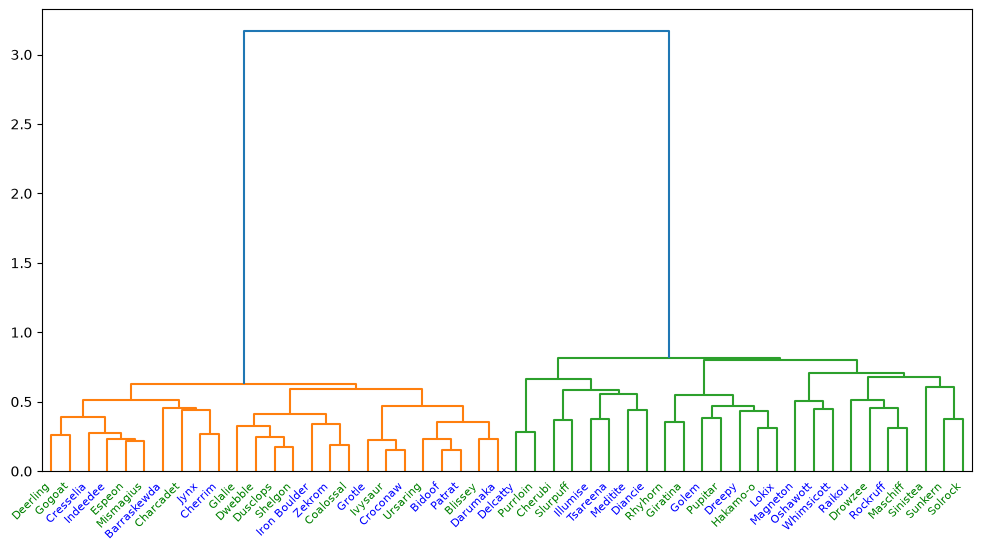

In [28]:
linkage_data = linkage(cond_distance_matrix, method='ward')

plt.figure(figsize=(12, 6))
ax = plt.subplot(111)
dendrogram(linkage_data, labels=df["name"])

for xtick in ax.get_xticklabels():
    label = xtick.get_text()
    if label not in image_dict:
        raise ValueError(f"Label {label} missing from dict")
    if image_dict[xtick.get_text()]:
        xtick.set_color('b')
    else:
        xtick.set_color('g')

plt.xticks(rotation=45, ha="right")


plt.savefig("test_cluster.png")
plt.show()